Extracting dataset.zip...
Data directory: /content/etdd70_extracted/data
Loaded 70 subjects successfully (35 Dyslexic, 35 Typical).
Training biomarker representation on cpu...


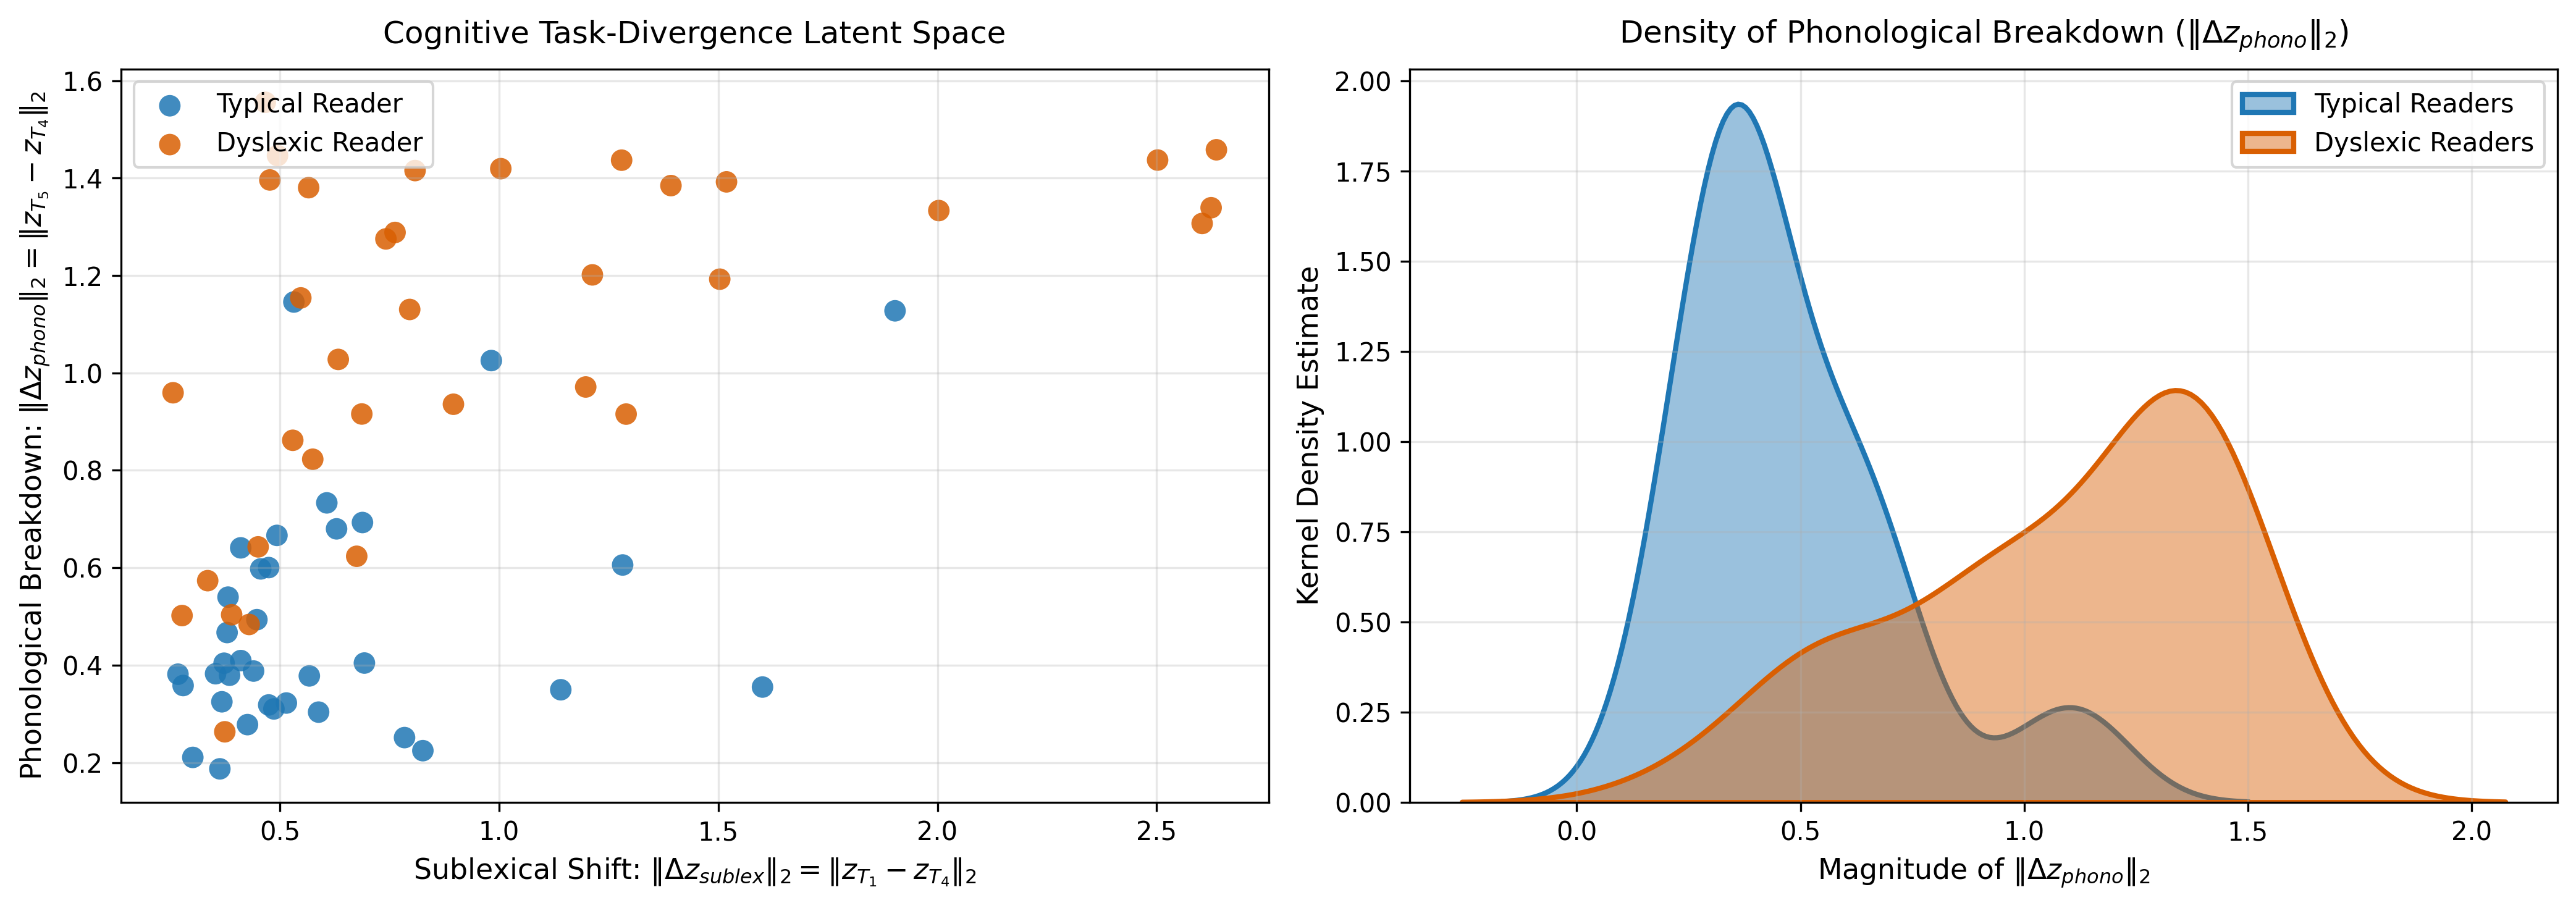

Saved complete biomarker figure to: /content/figures/cognitive_disparity_biomarker.png


In [2]:
import os
import glob
import re
import zipfile
import requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import StandardScaler

# =====================================================================
# 1. VERIFY FILES & DATASET EXTRACTION
# =====================================================================
if not os.path.exists("/content/etdd70_extracted") and os.path.exists("/content/dataset.zip"):
    print("Extracting dataset.zip...")
    with zipfile.ZipFile("/content/dataset.zip", 'r') as zip_ref:
        zip_ref.extractall("/content/etdd70_extracted")

candidate_dirs = [
    "/content/etdd70_extracted/data",
    "/content/etdd70_extracted",
    "/content/data"
]
DATA_DIR = next((d for d in candidate_dirs if os.path.exists(d) and len(glob.glob(os.path.join(d, "Subject_*"))) > 0), None)

if DATA_DIR is None:
    raise FileNotFoundError("Could not find Subject_* files. Please check /content/etdd70_extracted.")

print(f"Data directory: {DATA_DIR}")

# Download labels file if missing
label_file = "/content/dyslexia_class_label.csv"
if not os.path.exists(label_file):
    print("Downloading dyslexia_class_label.csv from Zenodo...")
    r = requests.get("https://zenodo.org/api/records/13332134").json()
    entries = r.get("files", {}).get("entries", []) if isinstance(r.get("files"), dict) else r.get("files", [])
    for f in entries:
        fname = f.get("key") or f.get("filename")
        if fname == "dyslexia_class_label.csv":
            url = f.get("links", {}).get("content") or f.get("links", {}).get("self")
            with open(label_file, "wb") as out:
                out.write(requests.get(url).content)
            break

# =====================================================================
# 2. LOAD SUBJECTS, SEQUENCES, AND LABELS
# =====================================================================
df_labels = pd.read_csv(label_file)
subject_label_map = {str(row['subject_id']): float(row['class_id']) for _, row in df_labels.iterrows()}

t1_files = sorted(glob.glob(os.path.join(DATA_DIR, "Subject_*_T1_Syllables_fixations.csv")))
subject_ids = [re.search(r"Subject_(\d+)_", f).group(1) for f in t1_files]

raw_t1, raw_t4, raw_t5 = [], [], []
stats_list, labels_list = [], []

for sid in subject_ids:
    f_t1 = os.path.join(DATA_DIR, f"Subject_{sid}_T1_Syllables_fixations.csv")
    f_t4 = os.path.join(DATA_DIR, f"Subject_{sid}_T4_Meaningful_Text_fixations.csv")
    f_t5 = os.path.join(DATA_DIR, f"Subject_{sid}_T5_Pseudo_Text_fixations.csv")

    df1 = pd.read_csv(f_t1).select_dtypes(include=[np.number]).dropna().iloc[:, :5]
    df4 = pd.read_csv(f_t4).select_dtypes(include=[np.number]).dropna().iloc[:, :5]
    df5 = pd.read_csv(f_t5).select_dtypes(include=[np.number]).dropna().iloc[:, :5]

    raw_t1.append(df1.to_numpy(dtype=np.float32))
    raw_t4.append(df4.to_numpy(dtype=np.float32))
    raw_t5.append(df5.to_numpy(dtype=np.float32))

    # 30 statistical features (10 from each task metrics file)
    m_t1 = pd.read_csv(os.path.join(DATA_DIR, f"Subject_{sid}_T1_Syllables_metrics.csv"))
    m_t4 = pd.read_csv(os.path.join(DATA_DIR, f"Subject_{sid}_T4_Meaningful_Text_metrics.csv"))
    m_t5 = pd.read_csv(os.path.join(DATA_DIR, f"Subject_{sid}_T5_Pseudo_Text_metrics.csv"))

    drop_cols = [c for c in m_t1.columns if any(k in c.lower() for k in ['id', 'subject', 'name', 'task'])]
    s1 = m_t1.drop(columns=[c for c in drop_cols if c in m_t1.columns], errors='ignore').select_dtypes(include=[np.number]).to_numpy().flatten()
    s4 = m_t4.drop(columns=[c for c in drop_cols if c in m_t4.columns], errors='ignore').select_dtypes(include=[np.number]).to_numpy().flatten()
    s5 = m_t5.drop(columns=[c for c in drop_cols if c in m_t5.columns], errors='ignore').select_dtypes(include=[np.number]).to_numpy().flatten()

    combined_stats = np.concatenate([s1[:10], s4[:10], s5[:10]])
    if len(combined_stats) < 30:
        combined_stats = np.pad(combined_stats, (0, 30 - len(combined_stats)), mode='constant')
    stats_list.append(combined_stats[:30])

    labels_list.append(subject_label_map[sid])

all_lens = [len(s) for s in (raw_t1 + raw_t4 + raw_t5)]
max_len = int(np.percentile(all_lens, 75))

def format_and_scale(raw_seqs, target_len):
    N = len(raw_seqs)
    arr = np.zeros((N, target_len, 5), dtype=np.float32)
    for i, seq in enumerate(raw_seqs):
        l = min(len(seq), target_len)
        arr[i, :l, :] = seq[:l, :5]
    flat = arr.reshape(-1, 5)
    scaler = StandardScaler().fit(flat)
    scaled = scaler.transform(flat).reshape(N, target_len, 5)
    return np.transpose(scaled, (0, 2, 1))

data_t1 = format_and_scale(raw_t1, max_len)
data_t4 = format_and_scale(raw_t4, max_len)
data_t5 = format_and_scale(raw_t5, max_len)
data_stats = StandardScaler().fit_transform(np.array(stats_list, dtype=np.float32))
labels = np.array(labels_list, dtype=np.float32)

print(f"Loaded {len(labels)} subjects successfully (35 Dyslexic, 35 Typical).")

# =====================================================================
# 3. DEFINE CTD-TCN ARCHITECTURE
# =====================================================================
class Chomp1d(nn.Module):
    def __init__(self, chomp_size: int):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return x[:, :, :-self.chomp_size].contiguous() if self.chomp_size > 0 else x

class TemporalResidualBlock(nn.Module):
    def __init__(self, in_ch: int, out_ch: int, kernel_size: int, dilation: int, dropout: float = 0.2):
        super().__init__()
        pad = (kernel_size - 1) * dilation
        self.conv1 = nn.Conv1d(in_ch, out_ch, kernel_size, padding=pad, dilation=dilation)
        self.chomp1 = Chomp1d(pad)
        self.bn1 = nn.BatchNorm1d(out_ch)
        self.drop1 = nn.Dropout(dropout)

        self.conv2 = nn.Conv1d(out_ch, out_ch, kernel_size, padding=pad, dilation=dilation)
        self.chomp2 = Chomp1d(pad)
        self.bn2 = nn.BatchNorm1d(out_ch)
        self.drop2 = nn.Dropout(dropout)

        self.downsample = nn.Conv1d(in_ch, out_ch, 1) if in_ch != out_ch else None
        self.act = nn.GELU()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        res = x if self.downsample is None else self.downsample(x)
        out = self.drop1(self.act(self.bn1(self.chomp1(self.conv1(x)))))
        out = self.drop2(self.act(self.bn2(self.chomp2(self.conv2(out)))))
        return self.act(out + res)

class SharedTCNEncoder(nn.Module):
    def __init__(self, in_features=5, hidden_dims=[32, 64, 64], kernel_size=3, dropout=0.2):
        super().__init__()
        layers = []
        for i in range(len(hidden_dims)):
            d = 2 ** i
            in_c = in_features if i == 0 else hidden_dims[i - 1]
            out_c = hidden_dims[i]
            layers.append(TemporalResidualBlock(in_c, out_c, kernel_size, dilation=d, dropout=dropout))
        self.net = nn.Sequential(*layers)
        self.latent_dim = hidden_dims[-1]

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.mean(self.net(x), dim=2)

class CognitiveTaskDivergenceNet(nn.Module):
    def __init__(self, in_features=5, stat_features=30, hidden_dims=[32, 64, 64], dropout=0.25):
        super().__init__()
        self.encoder = SharedTCNEncoder(in_features, hidden_dims, dropout=dropout)
        fused_dim = (self.encoder.latent_dim * 4) + stat_features
        self.classifier = nn.Sequential(
            nn.Linear(fused_dim, 64),
            nn.BatchNorm1d(64),
            nn.GELU(),
            nn.Dropout(dropout),
            nn.Linear(64, 16),
            nn.GELU(),
            nn.Linear(16, 1)
        )

    def forward(self, x_t1, x_t4, x_t5, x_stat):
        z1 = self.encoder(x_t1)
        z4 = self.encoder(x_t4)
        z5 = self.encoder(x_t5)
        delta_phono = torch.abs(z5 - z4)
        delta_sublex = torch.abs(z1 - z4)
        fused = torch.cat([z4, z5, delta_phono, delta_sublex, x_stat], dim=-1)
        logits = self.classifier(fused).squeeze(-1)
        return logits, delta_phono, delta_sublex

class CTDLoss(nn.Module):
    def __init__(self, lambda_reg=0.1, margin=1.0):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()
        self.lambda_reg = lambda_reg
        self.margin = margin

    def forward(self, logits, targets, delta_phono):
        cls_loss = self.bce(logits, targets)
        norm_delta = torch.norm(delta_phono, p=2, dim=1)
        reg_loss = (1.0 - targets) * torch.pow(norm_delta, 2) + targets * torch.pow(F.relu(self.margin - norm_delta), 2)
        return cls_loss + (self.lambda_reg * torch.mean(reg_loss))

# =====================================================================
# 4. TRAIN MODEL & EXTRACT DISPARITY METRICS
# =====================================================================
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Training biomarker representation on {device}...")

t1_tensor = torch.tensor(data_t1, dtype=torch.float32)
t4_tensor = torch.tensor(data_t4, dtype=torch.float32)
t5_tensor = torch.tensor(data_t5, dtype=torch.float32)
stat_tensor = torch.tensor(data_stats, dtype=torch.float32)
lbl_tensor = torch.tensor(labels, dtype=torch.float32)

loader = DataLoader(TensorDataset(t1_tensor, t4_tensor, t5_tensor, stat_tensor, lbl_tensor), batch_size=8, shuffle=True)

model = CognitiveTaskDivergenceNet().to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-2)
criterion = CTDLoss(lambda_reg=0.1, margin=1.0)

model.train()
for epoch in range(45):
    for b_t1, b_t4, b_t5, b_st, b_y in loader:
        b_t1, b_t4, b_t5, b_st, b_y = b_t1.to(device), b_t4.to(device), b_t5.to(device), b_st.to(device), b_y.to(device)
        optimizer.zero_grad()
        logits, d_phono, _ = model(b_t1, b_t4, b_t5, b_st)
        loss = criterion(logits, b_y, d_phono)
        loss.backward()
        optimizer.step()

model.eval()
norm_phono_list, norm_sublex_list = [], []

with torch.no_grad():
    for i in range(len(labels)):
        t1 = t1_tensor[i:i+1].to(device)
        t4 = t4_tensor[i:i+1].to(device)
        t5 = t5_tensor[i:i+1].to(device)

        z1 = model.encoder(t1)
        z4 = model.encoder(t4)
        z5 = model.encoder(t5)

        norm_phono_list.append(torch.norm(z5 - z4, p=2, dim=1).item())
        norm_sublex_list.append(torch.norm(z1 - z4, p=2, dim=1).item())

norm_phono = np.array(norm_phono_list)
norm_sublex = np.array(norm_sublex_list)
labels_arr = np.array(labels, dtype=int)

# =====================================================================
# 5. GENERATE FIGURE 5 (BIVARIATE SCATTER & DUAL-CURVE KDE)
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5), dpi=300)
palette = {0: '#1f77b4', 1: '#d95f02'}

# Left: Bivariate Scatter
for lbl, name in [(0, 'Typical Reader'), (1, 'Dyslexic Reader')]:
    idx = (labels_arr == lbl)
    axes[0].scatter(norm_sublex[idx], norm_phono[idx], c=palette[lbl], label=name, alpha=0.85, s=70, edgecolors='none')

axes[0].set_title("Cognitive Task-Divergence Latent Space", fontsize=12, pad=10)
axes[0].set_xlabel(r"Sublexical Shift: $\|\Delta z_{sublex}\|_2 = \|z_{T_1} - z_{T_4}\|_2$", fontsize=11)
axes[0].set_ylabel(r"Phonological Breakdown: $\|\Delta z_{phono}\|_2 = \|z_{T_5} - z_{T_4}\|_2$", fontsize=11)
axes[0].legend(frameon=True, loc='upper left')
axes[0].grid(True, alpha=0.3)

# Right: Dual-Curve KDE Density
sns.kdeplot(x=norm_phono[labels_arr == 0], ax=axes[1], fill=True, color='#1f77b4', label='Typical Readers', alpha=0.45, linewidth=2)
sns.kdeplot(x=norm_phono[labels_arr == 1], ax=axes[1], fill=True, color='#d95f02', label='Dyslexic Readers', alpha=0.45, linewidth=2)

axes[1].set_title(r"Density of Phonological Breakdown $(\|\Delta z_{phono}\|_2)$", fontsize=12, pad=10)
axes[1].set_xlabel(r"Magnitude of $\|\Delta z_{phono}\|_2$", fontsize=11)
axes[1].set_ylabel("Kernel Density Estimate", fontsize=11)
axes[1].legend(frameon=True, loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()

# Save for paper
os.makedirs("/content/figures", exist_ok=True)
save_path = "/content/figures/cognitive_disparity_biomarker.png"
plt.savefig(save_path, dpi=300)
plt.show()

print(f"Saved complete biomarker figure to: {save_path}")

Plotting Scanpaths: Typical = Subject 1003, Dyslexic = Subject 1009


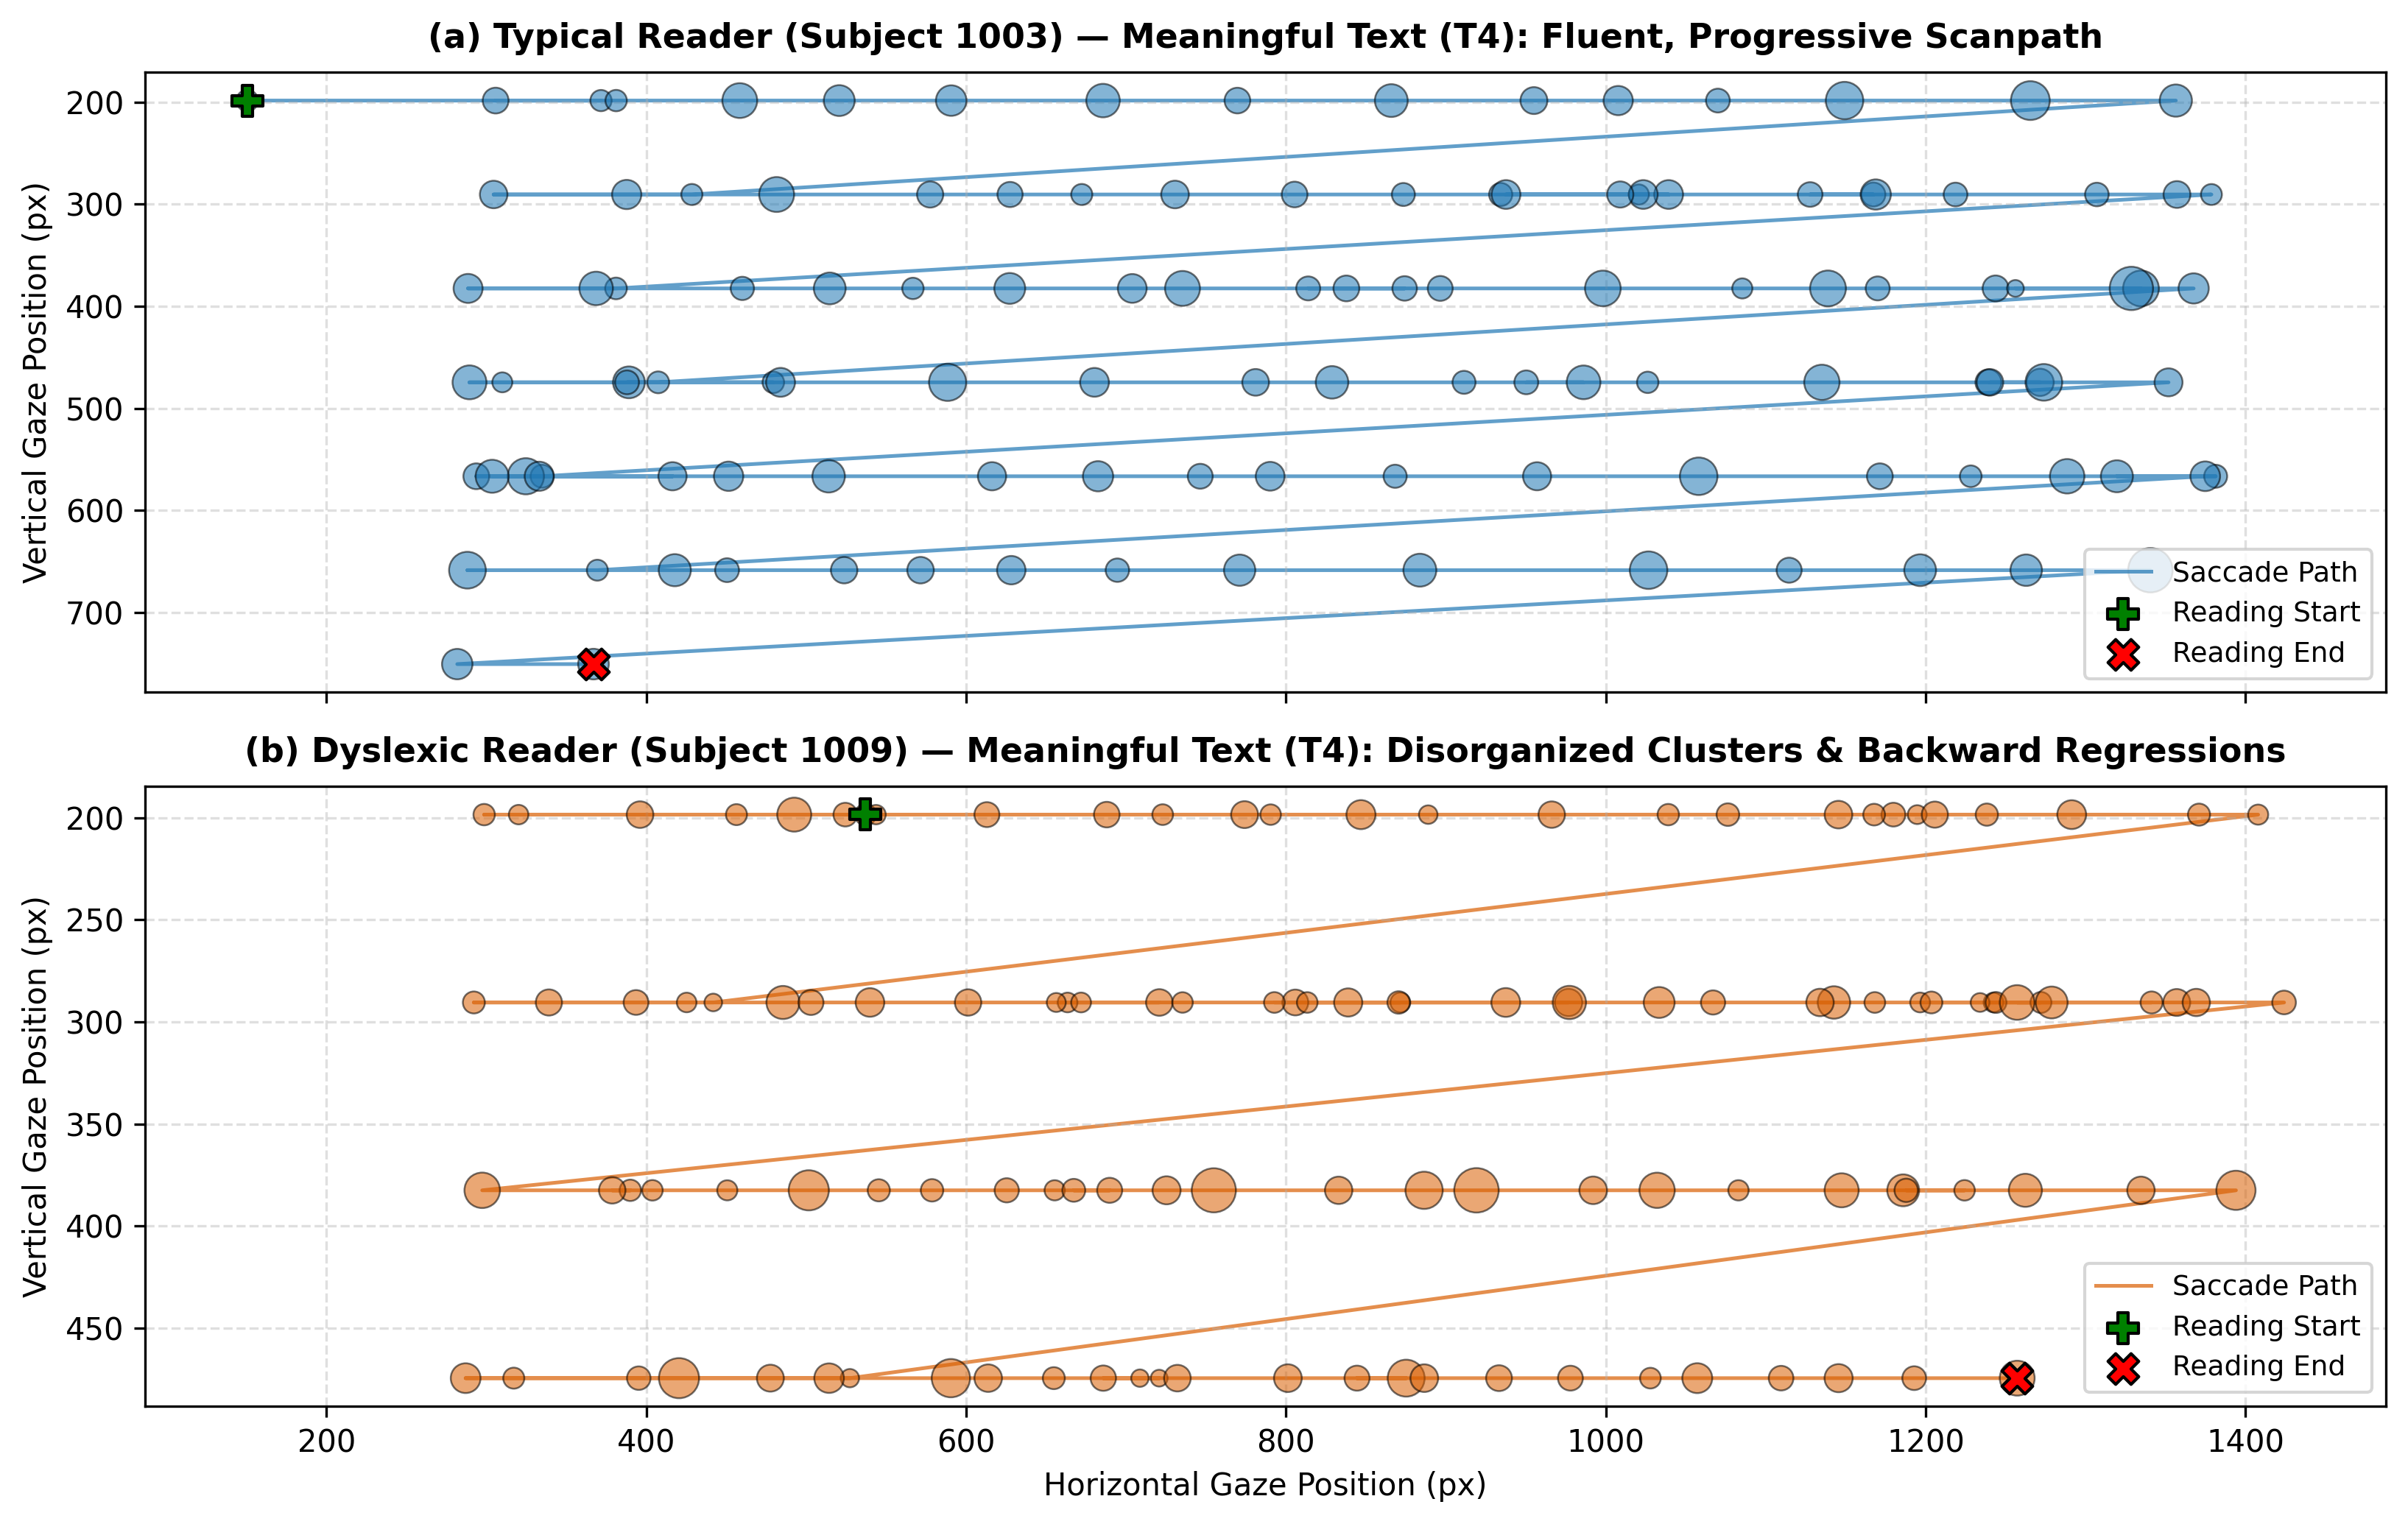

Successfully generated authentic Figure 1 and saved to: /content/figures/scanpath_comparison.png


In [3]:
import os
import glob
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Locate data directory
candidate_dirs = [
    "/content/etdd70_extracted/data",
    "/content/etdd70_extracted",
    "/content/data"
]
DATA_DIR = next((d for d in candidate_dirs if os.path.exists(d) and len(glob.glob(os.path.join(d, "Subject_*"))) > 0), None)

# 2. Identify one Typical Reader (class 0) and one Dyslexic Reader (class 1)
df_labels = pd.read_csv("/content/dyslexia_class_label.csv")
typical_id = str(df_labels[df_labels['class_id'] == 0]['subject_id'].iloc[0])   # e.g., Subject 1003
dyslexic_id = str(df_labels[df_labels['class_id'] == 1]['subject_id'].iloc[0])  # e.g., first dyslexic subject

print(f"Plotting Scanpaths: Typical = Subject {typical_id}, Dyslexic = Subject {dyslexic_id}")

def load_gaze_coords(sid, task_prefix):
    pattern = os.path.join(DATA_DIR, f"Subject_{sid}_{task_prefix}_fixations.csv")
    files = glob.glob(pattern)
    if not files:
        raise FileNotFoundError(f"Missing file for subject {sid}: {pattern}")
    df = pd.read_csv(files[0])

    # Identify X, Y coordinate columns and Duration
    num_cols = df.select_dtypes(include=[np.number]).columns.tolist()

    x_col = next((c for c in df.columns if any(k in c.lower() for k in ['fix_x', 'pos_x', 'avg_x', 'x_coord'])), num_cols[1])
    y_col = next((c for c in df.columns if any(k in c.lower() for k in ['fix_y', 'pos_y', 'avg_y', 'y_coord'])), num_cols[2])
    dur_col = next((c for c in df.columns if any(k in c.lower() for k in ['dur', 'time', 'length'])), num_cols[0])

    clean_df = df[[x_col, y_col, dur_col]].dropna().head(120)  # first 120 fixations
    return clean_df[x_col].values, clean_df[y_col].values, clean_df[dur_col].values

# Load Meaningful Text (T4) fixations
x_typ, y_typ, dur_typ = load_gaze_coords(typical_id, "T4_Meaningful_Text")
x_dys, y_dys, dur_dys = load_gaze_coords(dyslexic_id, "T4_Meaningful_Text")

# Normalize duration for bubble scaling
scale_typ = 30 + 180 * (dur_typ - dur_typ.min()) / (dur_typ.max() - dur_typ.min() + 1e-5)
scale_dys = 30 + 180 * (dur_dys - dur_dys.min()) / (dur_dys.max() - dur_dys.min() + 1e-5)

# 3. Create High-Quality Scanpath Comparison Plot
fig, axes = plt.subplots(2, 1, figsize=(11, 7), dpi=300, sharex=True)

# Panel A: Typical Reader
axes[0].plot(x_typ, y_typ, color='#1f77b4', lw=1.2, alpha=0.7, zorder=1, label='Saccade Path')
axes[0].scatter(x_typ, y_typ, s=scale_typ, color='#1f77b4', alpha=0.55, edgecolors='black', linewidth=0.6, zorder=2)
axes[0].scatter(x_typ[0], y_typ[0], color='green', s=100, marker='P', edgecolors='black', label='Reading Start', zorder=3)
axes[0].scatter(x_typ[-1], y_typ[-1], color='red', s=100, marker='X', edgecolors='black', label='Reading End', zorder=3)
axes[0].set_title(f"(a) Typical Reader (Subject {typical_id}) — Meaningful Text (T4): Fluent, Progressive Scanpath", fontsize=11, weight='bold', pad=8)
axes[0].set_ylabel("Vertical Gaze Position (px)", fontsize=10)
axes[0].invert_yaxis()  # Eye trackers place (0,0) at top-left
axes[0].grid(True, linestyle='--', alpha=0.4)
axes[0].legend(loc='lower right', frameon=True, fontsize=9)

# Panel B: Dyslexic Reader
axes[1].plot(x_dys, y_dys, color='#d95f02', lw=1.2, alpha=0.7, zorder=1, label='Saccade Path')
axes[1].scatter(x_dys, y_dys, s=scale_dys, color='#d95f02', alpha=0.55, edgecolors='black', linewidth=0.6, zorder=2)
axes[1].scatter(x_dys[0], y_dys[0], color='green', s=100, marker='P', edgecolors='black', label='Reading Start', zorder=3)
axes[1].scatter(x_dys[-1], y_dys[-1], color='red', s=100, marker='X', edgecolors='black', label='Reading End', zorder=3)
axes[1].set_title(f"(b) Dyslexic Reader (Subject {dyslexic_id}) — Meaningful Text (T4): Disorganized Clusters & Backward Regressions", fontsize=11, weight='bold', pad=8)
axes[1].set_xlabel("Horizontal Gaze Position (px)", fontsize=10)
axes[1].set_ylabel("Vertical Gaze Position (px)", fontsize=10)
axes[1].invert_yaxis()
axes[1].grid(True, linestyle='--', alpha=0.4)
axes[1].legend(loc='lower right', frameon=True, fontsize=9)

plt.tight_layout()

# Save image in the figures directory for LaTeX
os.makedirs("/content/figures", exist_ok=True)
output_path = "/content/figures/scanpath_comparison.png"
plt.savefig(output_path, dpi=300)
plt.savefig("/content/scanpath_comparison.png", dpi=300)
plt.show()

print(f"Successfully generated authentic Figure 1 and saved to: {output_path}")